# IBM AML HI-Small · Motif Finding có bằng chứng
## Khánh · Trình bày và kiểm chứng

**Câu hỏi:** có mẫu quan hệ nào giúp tìm ứng viên fraud/laundering tốt hơn chỉ nhìn một giao dịch?

**Dataset:** IBM HI-Small, 518.581 tài khoản Bank–Account và 5.078.345 giao dịch. `isFraud` là alias của `Is Laundering`; amount giữ nguyên payment currency, `step` là epoch seconds.

**Mạch trình bày:** review ETL → toy → baseline → motif theo thời gian → chọn trên validation → test và phản ví dụ → review LPA.

Code thuật toán nằm trong các module Python được **import ở từng bước**. Ctrl+click tên hàm/import để đọc source; notebook giữ lời gọi, bảng kết quả và hình. Không sao chép các định nghĩa hàm dài vào phần trình bày.

**Chạy:** Windows `.venv\Scripts\python.exe` → Restart Kernel → Run All. Spark `local[2]`, heap 6 GiB, Windows Job Object giới hạn CPU/RAM và chỉ cho một tác vụ chạy. Mỗi notebook độc lập, chỉ đọc input dataset tương ứng; không xuất CSV/PNG/model vào repo. Temp/checkpoint nằm ngoài repo.


**Tài nguyên:** toàn bộ dữ liệu được giữ nguyên; heap Spark 5 GiB, hard job cap tối đa 8 GiB, CPU 10% và tối đa 2 logical CPUs. Guard giữ nguyên RAM/commit dự phòng. Cache trung gian được giải phóng trước bước tiếp theo; checkpoint có thể spill xuống ổ đĩa. Thông số thực tế và đỉnh bộ nhớ nằm ở cell môi trường/kết thúc.


## 1 · Môi trường

`NotebookSession` kiểm tra Windows Python 3.12, JDK 17, dependency pin và tạo Spark. Source: [presentation.py](../src/motif/presentation.py).

**Bảo vệ tài nguyên:** chỉ một notebook/CLI/gate được chạy; đóng kernel trước khi đổi notebook. Windows Job Object giới hạn cả Python/JVM ở tối đa 2 logical CPUs, CPU hard cap 10%, heap 6 GiB và tổng job commit 10 GiB trên máy 32 GiB. Admission giữ khoảng 8 GiB RAM/commit dự phòng; watchdog dừng job khi áp lực tài nguyên kéo dài. Không tự tăng giới hạn hay retry sau resource stop. Chưa có backend GPU được xác minh; CPU temperature không đo được tin cậy nên không có bảo đảm chống lỗi nguồn/tản nhiệt. Cell cuối lưu số đo tài nguyên của chính lần chạy.


**Bằng chứng thực thi:** xem `metadata.graphguard_execution` để biết trạng thái và số cell đã chạy; `graphguard_source_sha256` ghi source của lần chạy hoàn tất. Runner lưu sau mỗi cell và chỉ xác nhận hoàn tất khi toàn bộ cell PASS, source không đổi. Số đo cell cuối thuộc phiên thực thi được ghi trong metadata.


In [1]:
from pathlib import Path
import sys
from IPython.display import display

repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'requirements.txt').exists() and (p / 'src').is_dir())
sys.path.insert(0, str(repo))
from src.motif.presentation import NotebookSession
session = NotebookSession.start('ibm_aml', driver_memory='5g')
display(session.runtime)


[RESOURCE] One workload; CPU hard cap 10%; <=2 logical CPUs; job commit cap 8.0 GiB; RAM reserve 7.9 GiB


[RESOURCE] Effective Spark local[2], heap 5120m; spill before increasing RAM


,setting,value
0,dataset,ibm_aml
1,system,Windows
2,python,3.12.10
3,spark,3.5.1
4,graphframes,0.12.2
5,java,17.0.20.1
6,master,local[2]
7,driver_memory,5120m
8,pip_check,PASS
9,cpu_hard_cap_percent,10


## 2 · Review IBM ETL: dữ liệu có đúng trước khi tìm motif?

Đọc lại hai raw CSV, chạy suite schema/null/dangling/Bank–Account/currency/alias, rồi đối chiếu **hai chiều `exceptAll`** giữa raw-mapped và Parquet, có tính bội số. Không ghi đè dữ liệu. Log chi tiết nằm ở `etl.log` trong bộ nhớ.

Code mapping: [etl.py](../src/ibm_aml/etl.py); kiểm tra gốc: [test_ibm_aml_etl.py](../tests/test_ibm_aml_etl.py); hàm điều phối: [reviews.py](../src/motif/reviews.py).

**Quy ước thời gian của artifact hiện có:** raw timestamp không mang timezone. Parquet của project đã được tạo khi Spark dùng `Asia/Saigon` (UTC+7). Cell dưới đặt rõ cùng quy ước để tái lập mapping; không khẳng định đây là timezone tài chính do IBM cung cấp. Các phép motif sau đó dùng epoch `step` và elapsed time.


In [2]:
from src.motif.reviews import review_ibm_etl

# Tái lập đúng timezone của Parquet đã bàn giao, độc lập timezone máy chạy.
session.spark.conf.set('spark.sql.session.timeZone', 'Asia/Saigon')
etl = review_ibm_etl(session.spark, session.repo)
display(etl.counts)
display(etl.comparison)


,vertices,edges,status
0,518581,5078345,PASS


,table,raw_minus_parquet,parquet_minus_raw,status
0,vertices,0,0,PASS
1,edges,0,0,PASS


## 3 · Hiểu truy vấn bằng toy graph

Mẫu `A → B → C → A` có ba phép xoay. Ba đỉnh phải khác nhau để loại self-loop và vòng hai tài khoản. Toy tự tạo chỉ kiểm tra thuật toán, không phải bằng chứng thực nghiệm fraud.

Source: [toy_cycle.py](../src/motif/toy_cycle.py).


{'status': 'PASS',
 'pattern': '(a)-[e1]->(b);(b)-[e2]->(c);(c)-[e3]->(a)',
 'vertices': ['A', 'B', 'C'],
 'edges': [['A', 'B'], ['B', 'C'], ['C', 'A']],
 'raw_match_count': 3,
 'raw_matches': [['A', 'B', 'C'], ['B', 'C', 'A'], ['C', 'A', 'B']],
 'unique_cycle_count': 1,
 'unique_cycles': [['A', 'B', 'C']]}

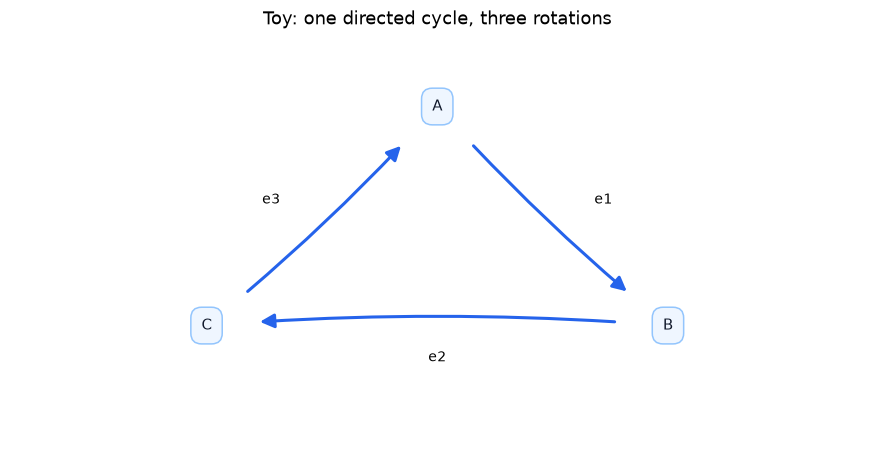

In [3]:
from src.motif.toy_cycle import run_demo
from src.motif.presentation import draw_graph

toy = run_demo(session.spark)
display(toy)
draw_graph({'A':'A', 'B':'B', 'C':'C'},
           [('A','B','e1'), ('B','C','e2'), ('C','A','e3')],
           'Toy: one directed cycle, three rotations')


## 4 · Baseline của Task 3

Audit trên cạnh đã gắn nhãn kiểm tra cấu trúc và phép đếm; **không phải detector không biết nhãn**. Truy vấn USD >10.000 được chạy riêng trên toàn graph. 7.473 raw matches, 2.491 tổ hợp giao dịch và 54 directed account cycles là ba đơn vị khác nhau.

Cell dưới **chạy lại truy vấn** và so các dòng bàn giao với CSV hiện có. Source: [motif_finding.py](../src/ibm_aml/motif_finding.py), điều phối hiển thị: [presentation.py](../src/motif/presentation.py).


In [4]:
from src.motif.presentation import baseline_audit

baseline = baseline_audit(session.spark, 'ibm_aml')
display(baseline.summary)
display(baseline.examples.head(5))


,dataset,fraud_edges,label_audit_raw_cycles,directed_account_cycles,transaction_combinations,USD_above_10000_cycles
0,ibm_aml,5177,7473,54,2491,0


,a,b,c,transaction_combinations
0,119_811C597B0,222_811B83280,48309_811C599A0,490
1,148350_811FFF630,148350_812D0C3C0,50528_812D0C600,360
2,119_811C597B0,150240_812D22980,48309_811C599A0,300
3,119_811C597B0,48309_811C599A0,150240_812D22980,280
4,119_811C597B0,222_811B83280,150240_812D22980,245


### Cycle từ kịch bản nguồn

Đọc Patterns và xác nhận từng cạnh minh họa có trong input hiện tại. Đây là audit nguồn, tách khỏi ví dụ TP của mô hình ở phần sau; không lấy kịch bản đã biết nhãn để giả lập detection.


In [5]:
from src.motif.reviews import review_documented_cycle

documented_cycle = review_documented_cycle(session.spark, session.repo)
display(documented_cycle)


,src,dst,timestamp,amount,payment_currency,amount_received,receiving_currency,payment_format,isFraud,source_line,matching_input_rows,source_three_hop_cycles
0,148350_811FFF630,148350_812D0C3C0,2022-09-05 18:42:00,48308.70,Saudi Riyal,48308.70,Saudi Riyal,ACH,1,2070,1,9
1,148350_812D0C3C0,50528_812D0C600,2022-09-07 12:52:00,43816.98,Saudi Riyal,43816.98,Saudi Riyal,ACH,1,2071,1,9
2,50528_812D0C600,148350_811FFF630,2022-09-07 18:12:00,42928.76,Saudi Riyal,42928.76,Saudi Riyal,ACH,1,2072,1,9


## 5 · Kiến trúc motif nâng cấp

| Feature | Mẫu / ý nghĩa |
|---|---|
| Fan-in | A → B ← C; có ít nhất một nguồn khác |
| Fan-out | A ← B → C; có ít nhất một đích khác |
| Relay | A → B → C; ba tài khoản khác nhau |
| Reciprocal | A → B → A; vòng hai tài khoản |
| Cycle 3 | A → B → C → A, thời gian tăng nghiêm ngặt |
| Role history | Số giao dịch vào/ra trước đó của người gửi/người nhận, kể cả sự vắng mặt của lịch sử |

Cửa sổ cố định **24 và 168 giờ**, quy đổi theo đơn vị của dataset. Witness luôn ở timestamp nhỏ hơn giao dịch hiện tại; các dòng cùng timestamp không làm chứng cứ cho nhau. Count là volume giao dịch, không phải số người khác nhau. Vòng hai tài khoản và ba tài khoản được đếm riêng.

Self-loop, FX và amount=0 không làm witness cho dòng tiền; vẫn giữ trong mẫu số đánh giá. Không so trực tiếp amount khác tiền tệ. Tài khoản/cặp chỉ có một timestamp có strict-past history bằng 0, được bỏ trước khi tạo marker; left join/fill-zero vẫn giữ đủ giao dịch. Counts dùng expiry events + unbounded prefix sums để tránh quét lại cửa sổ tại hub. Witness của cycle/reciprocal được giữ trực tiếp; fan-in/out/relay được truy vấn theo event ID khi cần giải thích, không sinh dày đặc cặp cạnh. Một giao dịch xuất hiện trong nhiều tổ hợp vẫn chỉ được dự đoán một lần.

IBM có nhiều typology. Mở rộng beyond 3-cycle tăng cơ hội bao phủ, nhưng không mặc định mọi fan-in/out đều đáng ngờ; cần đo đóng góp của chúng trên validation/test.

Source thuật toán: [features.py](../src/motif/features.py). Hướng dùng feature theo thời gian tham khảo [IBM AMLworld, Appendix D](https://arxiv.org/html/2306.16424v3#A4); đây là triển khai riêng, không tái hiện điểm số của bài báo.


### Protocol cố định trước đánh giá

- 3 fold mở rộng theo thời gian: train ≤40%, validate (40,50]; train ≤50%, validate (50,65]; train ≤65%, validate (65,80]. Giữ timestamp ties cùng tập.
- So **transaction-only** với **motif-assisted**, cùng cây quyết định độ sâu 5, cùng weighting và preprocessing. Thang amount q90 theo currency/type chỉ học từ prefix training. Không dùng raw account ID, absolute timestamp hoặc nhãn làm feature.
- Chọn family và score threshold theo mean validation F1, kiểm tra worst-fold/std, phá hòa ưu tiên mô hình đơn giản hơn. Có thể chọn transaction-only nếu motif không giúp; không ép chọn motif.
- Khóa rule rồi refit đến 80%; chấm phần sau 80%. Score từ cây có trọng số **không phải xác suất fraud đã hiệu chuẩn**.

**Giới hạn thực nghiệm:** phần test này đã được khám phá ở phiên bản trước; đây là **reused internal temporal holdout**, không phải benchmark mới chưa từng nhìn. Wilson 95% CI là khoảng mô tả theo giả định binomial; chưa hiệu chỉnh tương quan giữa giao dịch/tài khoản.

Source: [config.py](../src/motif/config.py), [modeling.py](../src/motif/modeling.py), [pipeline.py](../src/motif/pipeline.py).


In [6]:
from src.motif.config import AnalysisConfig
from src.motif.pipeline import prepare_experiment

config = AnalysisConfig(driver_memory="5g")
experiment = prepare_experiment(session.spark, 'ibm_aml', config=config)
display(experiment.support)
display(config.as_dict())


Features: star histories via expiry-prefix sums


Features: reciprocal and same-partner histories


Features: directed topology and chronological cycle evidence


,phase,transactions,fraud,first_step,last_step
0,initial_train,2032085,1052.0,1661965200,1662204600
1,validation_1,506937,694.0,1662204660,1662354900
2,validation_2,759843,809.0,1662354960,1662490020
3,validation_3,763916,825.0,1662490080,1662628320
4,reused_test,1015564,1797.0,1662628380,1663492680


{'windows_hours': (24, 168),
 'fold_fractions': (0.4, 0.5, 0.65, 0.8),
 'score_thresholds': (0.001,
  0.005,
  0.01,
  0.02,
  0.05,
  0.1,
  0.2,
  0.3,
  0.5,
  0.7,
  0.9,
  0.99),
 'tree_depth': 5,
 'minimum_leaf_rows': 50,
 'seed': 2026,
 'example_limit': 5,
 'driver_memory': '5g',
 'parallelism': 2}

### Chọn cấu hình trên validation

Feature builder không nhận nhãn. Bước chấm rủi ro dưới đây **có giám sát**: nó học từ nhãn training, rồi chọn threshold bằng validation. Việc kiểm soát dữ liệu nằm trong pipeline Python, dùng cùng API cho CLI và notebook.


Validation 1: transaction_only; training through 1662204600, validation through 1662354900


Validation 1: motif_assisted; training through 1662204600, validation through 1662354900


Validation 2: transaction_only; training through 1662354900, validation through 1662490020


Validation 2: motif_assisted; training through 1662354900, validation through 1662490020


Validation 3: transaction_only; training through 1662490020, validation through 1662628320


Validation 3: motif_assisted; training through 1662490020, validation through 1662628320


,family,threshold,mean_F1,worst_F1,std_F1,mean_precision,TP,FP,FN,transactions,folds
0,motif_assisted,0.50,0.095110,0.073824,0.031976,0.057563,761,14147,1567,2030696,3
1,motif_assisted,0.30,0.079462,0.073824,0.005558,0.044405,902,19254,1426,2030696,3
2,motif_assisted,0.70,0.051284,0.000000,0.077758,0.076244,221,2116,2107,2030696,3
3,motif_assisted,0.20,0.043537,0.037306,0.005419,0.022463,1673,74398,655,2030696,3
4,motif_assisted,0.10,0.041036,0.037306,0.005331,0.021129,1687,79246,641,2030696,3
5,transaction_only,0.50,0.034569,0.000000,0.059876,0.059051,351,5593,1977,2030696,3
6,transaction_only,0.30,0.034569,0.000000,0.059876,0.059051,351,5593,1977,2030696,3
7,motif_assisted,0.05,0.021790,0.013181,0.011377,0.011079,1880,201352,448,2030696,3


{'family': 'motif_assisted',
 'threshold': 0.5,
 'mean_F1': 0.09511011300621,
 'worst_F1': 0.073824312333629,
 'std_F1': 0.031976112437013,
 'mean_precision': 0.057562614170788,
 'TP': 761,
 'FP': 14147,
 'FN': 1567,
 'transactions': 2030696,
 'folds': 3}

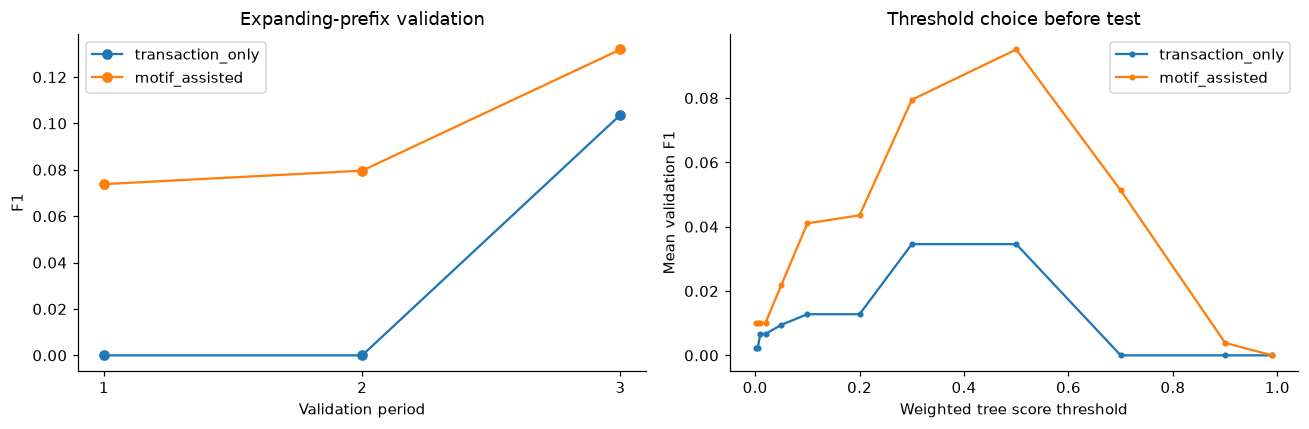

In [7]:
from src.motif.pipeline import run_walk_forward
from src.motif.presentation import plot_walk_forward

leaderboard = run_walk_forward(experiment)
display(leaderboard.head(8))
display(experiment.selection)
plot_walk_forward(experiment)


### Refit cấu hình đã khóa

Từ bước này không thay family/threshold theo kết quả test. Pipeline kiểm tra state và fingerprint cấu hình để phát hiện sửa rule sau validation.


In [8]:
from src.motif.pipeline import fit_final_models

training_info = fit_final_models(experiment)
display(training_info)


Refit frozen transaction_only; test is not used in fitting


Refit frozen motif_assisted; test is not used in fitting


{'transaction_only': {'train_end': 1662628320,
  'rows': 4062781,
  'fraud': 3380,
  'positive_class_weight': 34.65553654205561,
  'status': 'fitted'},
 'motif_assisted': {'train_end': 1662628320,
  'rows': 4062781,
  'fraud': 3380,
  'positive_class_weight': 34.65553654205561,
  'status': 'fitted'}}

### Đánh giá cuối: so công bằng với baseline transaction-only

Mẫu số gồm **mọi giao dịch** của test, không chỉ giao dịch nằm trong motif. Báo precision/recall/F1, average precision từ toàn bộ mức score của cây, CI và TP/FP/FN/TN. Một alert là đề nghị điều tra; không alert không chứng minh hợp pháp.


,model,threshold,TP,FP,FN,TN,precision,recall,F1,average_precision
0,transaction_only,0.5,885,9057,912,1004710,0.089016,0.492487,0.150779,0.056023
1,motif_assisted,0.5,474,4059,1323,1009708,0.104567,0.263773,0.149763,0.056472


,model,precision_low95,precision_high95,recall_low95,recall_high95
0,transaction_only,0.083576,0.094774,0.469413,0.515594
1,motif_assisted,0.095991,0.113812,0.243917,0.284636


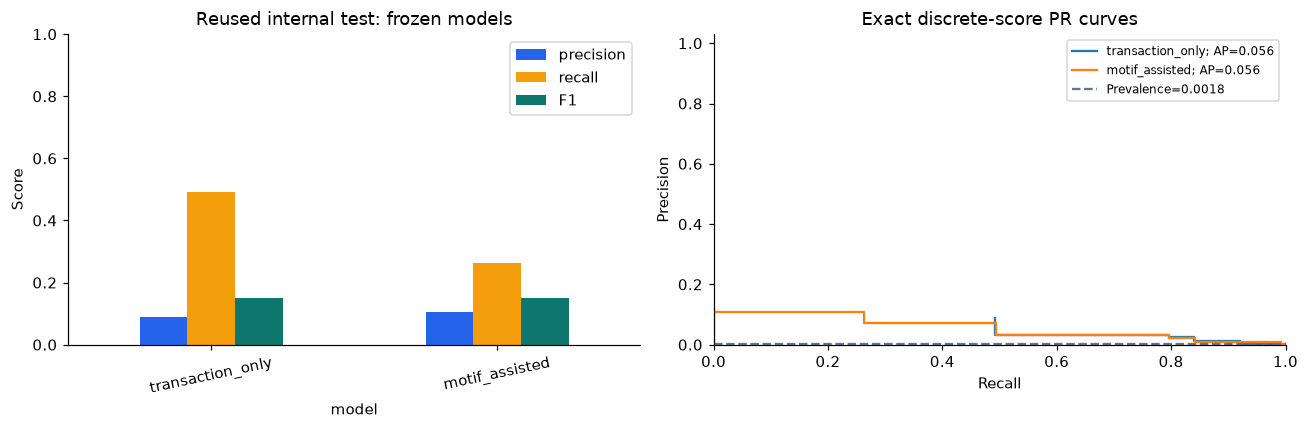

In [9]:
from src.motif.pipeline import evaluate_final_models
from src.motif.presentation import plot_test_results

metrics = evaluate_final_models(experiment)
display(metrics[['model','threshold','TP','FP','FN','TN','precision','recall','F1','average_precision']])
display(metrics[['model','precision_low95','precision_high95','recall_low95','recall_high95']])
plot_test_results(experiment)


### Motif có thực sự đóng góp?

Đọc ablation transaction-only ↔ motif-assisted trước khi kết luận. Feature importance mô tả cây đã học, không chứng minh quan hệ nhân quả. Coverage giữa các motif có thể chồng nhau, không cộng thành tổng fraud.


,motif,closing_transactions,fraud_closing_transactions
0,fanin,3286253,4016
1,fanout,3251885,2295
2,relay,3516472,2427
3,reciprocal,4455,305
4,cycle3,304,92


,feature,importance
0,scaled_amount,0.446489
1,type_index,0.417903
2,fanin_168h,0.091206
3,sender_out_24h,0.023714
4,reciprocal_168h,0.018789
5,fanin_24h,0.001899
6,unseen_amount_group,0.000000
7,currency_index,0.000000
8,receiver_in_24h,0.000000
9,sender_in_24h,0.000000


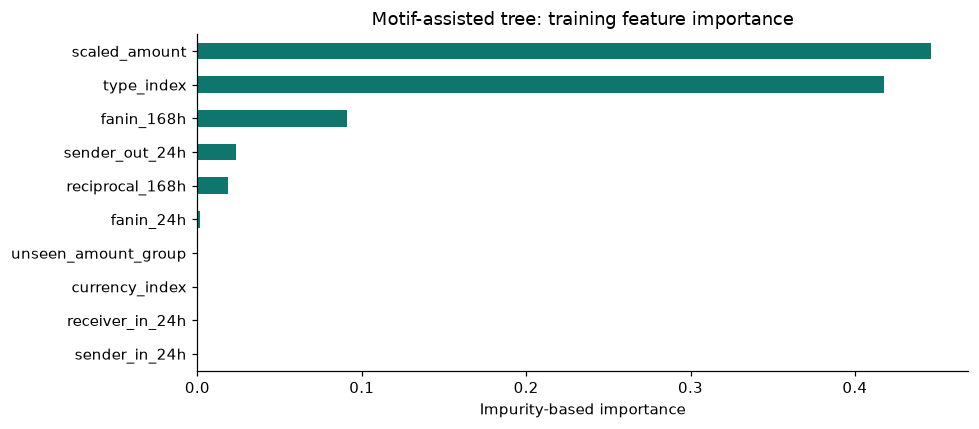

In [10]:
from src.motif.pipeline import motif_coverage
from src.motif.presentation import plot_feature_importance

display(motif_coverage(experiment))
display(experiment.models["motif_assisted"].importance().head(10))
plot_feature_importance(experiment)


### Phát hiện đúng, báo nhầm và bỏ sót

Hiển thị các trường hợp từ **mô hình được chọn trên validation**. Không thay bằng ví dụ từ truy vấn lọc nhãn. Một số TP có thể do thông tin giao dịch hoặc sự thiếu lịch sử, chứ không có motif nhiều cạnh dương tính.


TP — selected model, test period


,event_id,src,dst,type,amount,payment_currency,risk_score,isFraud
0,8590296449,1299_8009D3030,111764_807081420,ACH,13257.33,US Dollar,0.774002,1.0
1,481603,23842_8019C0990,1674_8006A6CF0,ACH,17576.30,US Dollar,0.774002,1.0
2,8592202278,11318_80081F5E0,410_80098DC70,ACH,6357.09,Euro,0.774002,1.0
3,8591585750,10_80CE8FDA0,19329_808B1C350,ACH,17904.38,US Dollar,0.774002,1.0
4,1057037,18460_808A58D40,28779_80A8A0F70,ACH,21719.16,Australian Dollar,0.774002,1.0


FP — selected model, test period


,event_id,src,dst,type,amount,payment_currency,risk_score,isFraud
0,8590420134,14650_801B3CA10,1547_801B3CD80,ACH,638.19,Euro,0.889618,0.0
1,8592330710,3489_801E0F9D0,14650_801E0F8E0,ACH,824.78,Euro,0.889618,0.0
2,1153407,220_8005E84E0,795_80039DEF0,ACH,477.31,US Dollar,0.889618,0.0
3,1783106,15625_8086E7510,1686_8086E7110,ACH,90.26,US Dollar,0.889618,0.0
4,1147151,18549_807AAE300,113798_807AADD30,ACH,836.33,US Dollar,0.889618,0.0


FN — selected model, test period


,event_id,src,dst,type,amount,payment_currency,risk_score,isFraud
0,8590332223,121_8000E1590,223_8119F8CC0,ACH,51203.66,Saudi Riyal,0.373756,1.0
1,8590985293,6156_8052E39D0,17769_8078C8600,ACH,7580.91,Euro,0.373756,1.0
2,8591009572,4_8007C5C80,16733_8069CC590,ACH,17987.24,US Dollar,0.373756,1.0
3,1363412,135981_80F984C70,29435_80DE48320,ACH,5960.62,Euro,0.373756,1.0
4,8591677081,2454_806E8ADD0,217125_8073CD950,ACH,1131798.67,Ruble,0.373756,1.0


,event_id,src,dst,step,amount,payment_currency,isFraud,role
0,250169,222_811B83280,48309_811C599A0,1662373080,50662.36,Saudi Riyal,1.0,past witness
1,981359,48309_811C599A0,119_811C597B0,1662639120,48259.06,Saudi Riyal,1.0,past witness
2,2438603,119_811C597B0,222_811B83280,1662698760,52873.69,Saudi Riyal,1.0,current alert


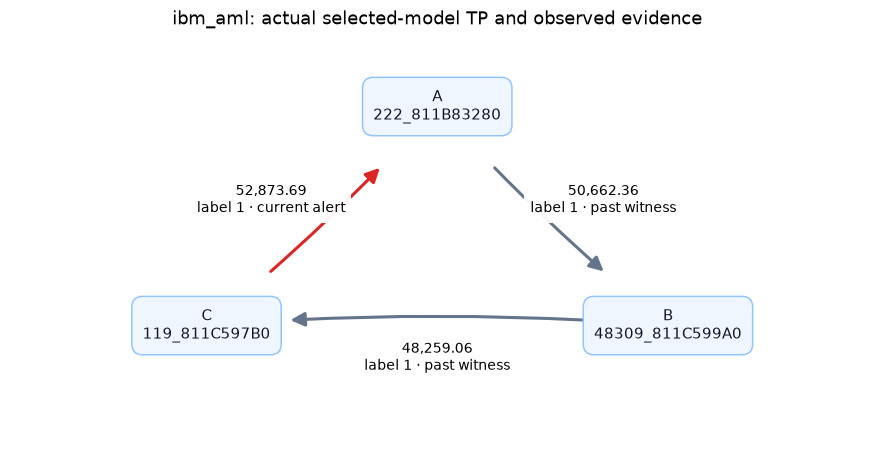

In [11]:
from src.motif.presentation import show_examples, motif_evidence, plot_evidence

show_examples(experiment)
evidence = motif_evidence(experiment)
display(evidence)
plot_evidence(evidence, session.dataset)


### Kết luận IBM từ output đã chạy

CV chọn **motif-assisted, weighted score ≥0,50**. Score có trọng số không phải xác suất fraud đã hiệu chuẩn.

| Model | Test TP | FP | FN | Precision | Recall | F1 | Average precision |
|---|---:|---:|---:|---:|---:|---:|---:|
| Transaction-only | 885 | 9.057 | 912 | 8,90% | 49,25% | 15,08% | 5,60% |
| Motif-assisted | 474 | 4.059 | 1.323 | 10,46% | 26,38% | 14,98% | 5,65% |

Mẫu số: **1.015.564 giao dịch / 1.797 laundering**. Motif-assisted giảm **4.998 FP (khoảng 55%)** nhưng bỏ sót thêm **411 fraud** so với transaction-only. F1 **giảm 0,10 điểm phần trăm**, AP chỉ tăng rất nhỏ; không kết luận motif cải thiện F1 trên IBM trong lần đánh giá này. Threshold được chọn từ validation, không chọn lại để làm đẹp bảng test. Mean validation F1 **9,51%**, worst-fold **7,38%**, std **3,20 điểm phần trăm**.

Trong toàn dataset, cycle ba tài khoản theo thời gian và giới hạn 168 giờ có **304 giao dịch đóng vòng / 92 giao dịch laundering**. Reciprocal có **4.455 / 305**. Các coverage chồng nhau và không cộng thành tổng fraud. Khác với PaySim, IBM có ví dụ TP thật gồm ba cạnh theo thứ tự thời gian, cùng Saudi Riyal; nhãn chỉ được join sau khi mô hình quyết định. Cây có sử dụng fan-in và reciprocal; `cycle3_count` không được chọn làm split. Vòng TP là bằng chứng quan sát được của giao dịch cảnh báo, không chứng minh feature cycle gây ra quyết định. Một hình minh họa không chứng minh toàn bộ detector tốt.

Kết quả cho thấy mở rộng ra nhiều motif giải quyết được việc chỉ query USD >10.000 trả 0, nhưng phần lớn laundering vẫn cần thêm tín hiệu. Khi ghép PageRank/LPA, phải dùng snapshot quá khứ và đánh giá lại trên dữ liệu mới; không lấy fraud rate test làm feature. Đây vẫn là **reused internal temporal holdout**.

### Bàn giao để kết hợp PageRank/LPA

Giữ feature, witness, `event_key`, `event_id`, source/target và thời điểm. `event_key` là content fingerprint, **không duy nhất khi dữ liệu có dòng trùng**; `event_id` giữ từng dòng trong cùng lần chạy. Join PageRank/LPA theo tài khoản từ snapshot đến thời điểm quyết định. Không dùng tỷ lệ fraud của nhãn test làm feature.

CLI có thể xuất model, training amount scales, report, validation scores, ví dụ và run manifest có hash; `--export-features` xuất thêm Parquet cho tích hợp. Notebook này chỉ giữ output nhúng.


In [12]:
# Giải phóng cache của experiment trước phần review tiếp theo.
experiment.close()


## 6 · Review và final Task 4 IBM

Phần của Khánh là review code LPA của Hoàng: full graph, checker độc lập, tiền tách theo currency; hai lần sample so **thành viên cụm**, bỏ qua việc đổi số label. `label` của LPA là community ID, không phải nhãn fraud. LPA này chưa được ghép vào mô hình chấm rủi ro ở trên.

Thuật toán: [community_detection.py](../src/ibm_aml/community_detection.py); checker: [verify_communities.py](../src/ibm_aml/verify_communities.py). Các lời gọi và quản lý cache: [reviews.py](../src/motif/reviews.py).


,vertices,assigned_vertices,edges,communities,summary_rows,internal_edges,cross_edges,fraud_edges,amount_currency_rows
0,518581,518581,5078345,314829,314829,853796,4224549,5177,314577


,label,member_count,unique_banks_count,avg_balance,total_tx_count,laundering_tx_count,internal_tx_count,internal_laundering_count,laundering_rate
0,171798707604,6918,1261,0.0,41702,66,8338,0,0.0016
1,77309427222,4660,828,0.0,29996,46,5948,1,0.0015
2,17179873433,2870,1321,0.0,184296,257,3219,2,0.0014
3,180388626803,1171,709,0.0,108626,166,832,0,0.0015
4,206158445889,836,174,0.0,4956,2,993,0,0.0004
5,51539623360,799,152,0.0,5420,4,952,0,0.0007
6,68719492420,792,131,0.0,5479,6,1065,1,0.0011
7,94489296328,764,126,0.0,5394,3,884,0,0.0006


,same_partition,accounts_with_changed_canonical_community,accounts,interpretation
0,True,0,119043,observed comparison; differences do not invali...


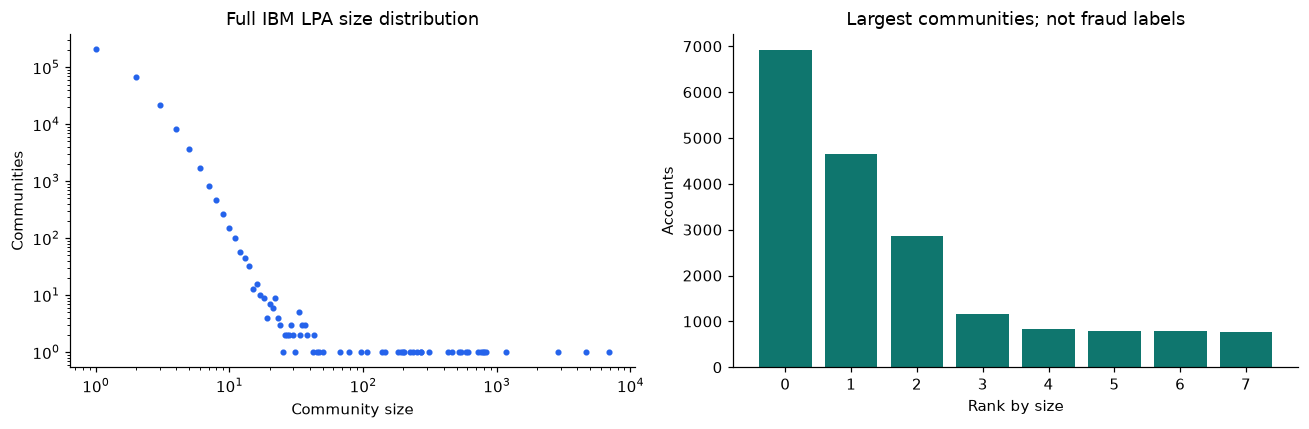

In [13]:
from src.motif.reviews import review_ibm_lpa
from src.motif.presentation import plot_lpa

lpa = review_ibm_lpa(session.spark, session.repo, session.checkpoint)
display(lpa.metrics)
display(lpa.overview)
display(lpa.stability)
plot_lpa(lpa)


### Guardrail của checker

Checker phải từ chối account trùng/thiếu, label null/phân số, amount NaN và summary cộng tiền không tách currency. Đây là kiểm tra tính đúng, không phải bằng chứng các cộng đồng là gian lận.


In [14]:
from src.motif.reviews import review_checker_guardrails

display(lpa.amounts)
display(review_checker_guardrails(session.spark))


,label,payment_currency,total_tx_count,total_tx_amount
0,17179873433,US Dollar,184184,5.628903e+10
1,8589939865,US Dollar,80,1.978677e+10
2,60129547804,US Dollar,4,1.662837e+10
3,171798707604,US Dollar,41456,1.521678e+10
4,206158434720,US Dollar,26,1.380815e+10
5,6792,US Dollar,10,1.379447e+10
6,60129548835,US Dollar,10,7.976476e+09
7,9530,US Dollar,6,7.027710e+09


[PASS] Exact account coverage and non-null integer labels: 2


,case,status,reason
0,duplicate account,PASS: rejected,assignments: duplicate keys
1,missing account,PASS: rejected,assignments: incomplete or foreign keys (missi...
2,null label,PASS: rejected,Invalid numeric values in ['label']
3,fractional label,PASS: rejected,Invalid numeric values in ['label']
4,NaN amount,PASS: rejected,Invalid numeric values in ['amount']
5,mixed-currency summary field,PASS: rejected,Ambiguous total_tx_amount in community summary...


## 7 · Chốt kết quả và phiên bản code

Khi bảo vệ: nêu baseline → motif/feature → protocol → ablation/test → một TP/FP/FN → giới hạn. Không dùng số test để chọn lại cấu hình. PASS kỹ thuật không xác nhận chất lượng detector hay phê duyệt của người review.

Các nhiệm vụ của Khánh được giữ: review ETL (28/9), Task 3 IBM (1–6/10), review/final Task 4 IBM (5–7/10). Phần mở rộng v2 bổ sung pipeline, motifs theo thời gian và đánh giá chấm rủi ro; không thay số baseline để ép kết quả.


In [15]:
from src.motif.presentation import source_provenance

display(source_provenance())
display(session.close())


,source,sha256
0,src/motif/__init__.py,f42e40287d3de4006d8e0d042b61b38f5726b414b2b949...
1,src/motif/config.py,ced62e7f1f0832ea19b58ff3b479cab960bc9e3eb34197...
2,src/motif/evaluation.py,8746e78334ae5fe5206d68b733dee439254e41c2c01280...
3,src/motif/features.py,c003976414ee220264914ee17ebcf6032be257d63b88c5...
4,src/motif/modeling.py,bf745456bdbc262ffad2e0120484222c634adfa64b9860...
5,src/motif/pipeline.py,fadf770fe5af77488cb4f39e6087430bc637f6f6806cc6...
6,src/motif/presentation.py,84881e6eb3209512321ada71fca66f57686761ff175b23...
7,src/motif/reviews.py,11a6b62d1e13edb9b06e60959169448672c2d49470cbc7...
8,src/motif/toy_cycle.py,44caa76842030eb834f9e854fd7f8b18cd5aabf2498f47...
9,src/common/graph_utils.py,0f3927e16594eda2a2fff6b0b43c6fc7c54629a25e85fb...


,setting,value
0,dataset,ibm_aml
1,finished_utc,2026-10-22T15:49:25.979771+00:00
2,elapsed_seconds,1851.0
3,execution,Completed; performance is reported separately
4,cpu_hard_cap_percent,10
5,max_logical_cpus,2
6,job_commit_cap_gib,8.0
7,peak_job_commit_gib,5.97
8,minimum_available_ram_gib,13.49
9,maximum_host_cpu_percent,62.1
